In [1]:
import pandas as pd
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import DBSCAN
import re
from sklearn.metrics import silhouette_score
from sklearn.model_selection import ParameterGrid

In [2]:
data = pd.read_csv('/Users/nicolasbour/Desktop/Projets_IA/Projets_certif/bloc_03_Machine_Learning/03_the_north_face/Nico/sample_clean.csv')

In [3]:
data.head()

,id,description_texte,details,fabric,weight,pays
0,1,active classic boxers - s reason boxers cult f...,"silky capilene 1 fabric ultralight , breathabl...",3.7 - oz 100 % - recycled polyester gladiodor ...,99 g 3.5 oz,Mexico
1,2,active sport boxer briefs - skinning glory req...,"stretch mesh provides support , open - weave m...",4.6 - oz 93 % polyester 71 % recycled /7 % spa...,60 g 2.1 oz,Israel
2,3,active sport briefs - superbreathable - fly br...,"stretch mesh provides support , open - weave m...",4.6 - oz 93 % polyester 71 % recycled /7 % spa...,49 g 1.7 oz,Israel
3,4,"alpine guide pants - skin , climb ice , switch...",durable stretch - woven polyester 47 % recycle...,7.6 - oz 90 - denier 92 % polyester 47 % recyc...,597 g 20.7 oz,Vietnam
4,5,"alpine wind jkt - high ridges , steep ice alpi...","lightweight , breathable polyester ripstop fab...",shell 1.3 - oz 20 - denier 100 % polyester rip...,331 g 11.5 oz,China


In [4]:
data.isnull().sum()

id                   0
description_texte    0
details              0
fabric               0
weight               8
pays                 8
dtype: int64

In [5]:
data.nunique()

id                   500
description_texte    488
details              420
fabric               223
weight               243
pays                  12
dtype: int64

In [6]:
data.shape

(500, 6)

In [7]:
colonnes_texte = ["description_texte", "details", "fabric", "weight", "pays"]

textes = data[colonnes_texte].fillna("").astype(str).agg(" ".join, axis=1)


In [8]:
display(textes.head())
print("Nombre de textes :", len(textes))

0    active classic boxers - s reason boxers cult f...
1    active sport boxer briefs - skinning glory req...
2    active sport briefs - superbreathable - fly br...
3    alpine guide pants - skin , climb ice , switch...
4    alpine wind jkt - high ridges , steep ice alpi...
dtype: object

Nombre de textes : 500


In [9]:
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_df=0.95,
    min_df=2
)

matrice_tfidf = vectorizer.fit_transform(textes)

print("Dimensions :", matrice_tfidf.shape)
print("Exemples de mots :", vectorizer.get_feature_names_out()[:20])

Dimensions : (500, 2619)
Exemples de mots : ['000' '10' '100' '103' '108' '109' '1096' '11' '112' '115' '118' '1188'
 '12' '1200' '121' '124' '126' '129' '13' '130']


In [10]:
pd.DataFrame(
    matrice_tfidf[:5].toarray(),
    columns=vectorizer.get_feature_names_out()
)

,000,10,100,103,108,109,1096,11,112,115,...,yoga,yoke,yosemite,zip,zipper,zippered,zippers,zipping,zips,zones
0,0.0,0.00000,0.082345,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
1,0.0,0.00000,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
2,0.0,0.00000,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
3,0.0,0.00000,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.239127,0.073411,0.0,0.0,0.0
4,0.0,0.04785,0.047210,0.0,0.0,0.0,0.0,0.060475,0.0,0.0,...,0.0,0.0,0.0,0.0,0.089452,0.035530,0.054538,0.0,0.0,0.0


In [11]:
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

svd = TruncatedSVD(n_components=100, random_state=42)
matrice_reduite = normalize(svd.fit_transform(matrice_tfidf))

print("Variance expliquée :", svd.explained_variance_ratio_.sum())

Variance expliquée : 0.6623443745410639


In [12]:
dbscan = DBSCAN(
    eps=0.5,
    min_samples=10,
    metric="cosine"
)

In [13]:
data["cluster"] = dbscan.fit_predict(matrice_reduite)

display(data["cluster"].value_counts().sort_index())

cluster
-1     141
 0      29
 1      10
 2      44
 3      64
 4      88
 5      28
 6      15
 7      13
 8      17
 9       9
 10     14
 11     18
 12     10
Name: count, dtype: int64

In [14]:
display(data.sort_values("cluster"))

,id,description_texte,details,fabric,weight,pays,cluster
252,253,"solid kupala - fixed triangle bikini , kupala ...",fixed triangle swim adjustable ties crossover ...,5.6 - oz 82 % nylon/18 % spandex,57 g 2 oz,USA,-1
415,416,micro puff vest - alpine shiver - fests leave ...,"ultralight , water - resistant windproof shell...",shell 1.5 - oz 32 - denier 100 % - recycled po...,288 g 10 oz,Thailand,-1
203,204,micro puff vest - alpine shiver - fests leave ...,"ultralight , windproof shell liner 100 % - rec...",shell 1.5 - oz 32 - denier 100 % - recycled po...,271 g 9.4 oz,Thailand,-1
408,409,"boardie shorts - let grom rip , tear shred - s...","soft , durable lightweight micropolyester quic...",3.7 - oz 100 % microfiber polyester brushed fa...,118 g 4.1 oz,Colombia,-1
117,118,"shop pants - reg - home truck inside , shop pa...",10 - oz year - round weight organic cotton can...,10 - oz 100 % organic cotton canvas . recyclab...,595 g 21 oz,Thailand,-1
...,...,...,...,...,...,...,...
296,297,versatiliti cardi - summer - weight cardigan w...,plaited organic cotton tencel fabric soft comf...,5.5 - oz 62 % organic cotton/38 % tencel plait...,184 g 6.4 oz,Thailand,12
182,183,gravitee tank - gravitee s racerback shelf bra...,"blend organic cotton tencel , touch spandex st...",6.1 - oz 54 % organic cotton/41 % tencel/5 % s...,213 g 7.4 oz,Thailand,12
122,123,special edition pataloha shirt - year s specia...,machine - washable blend organic cotton tencel...,3 - oz 55 % organic cotton/45 % tencel . recyc...,216 g 7.5 oz,Thailand,12
295,296,"versatili - tee - t - shirt food chain , versa...",plaited organic cotton tencel fabric soft comf...,5.5 - oz 62 % organic cotton/38 % tencel plait...,126 g 4.4 oz,Thailand,12


In [15]:
print(f"Nombre de clusters : {len(set(data['cluster'])) - 1}")  # On soustrait 1 pour exclure le bruit (-1)

Nombre de clusters : 13


Le cluster -1 est le cluster considéré comme du bruit par l'algorithme Dbscan. Nous allons tenter de réduire le nombre de produits dans ce cluster en ajustant les paramètres de l'algorithme.

In [16]:
parametres = {
    "eps": [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    "min_samples": [2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 15]
}

resultats = []

for params in ParameterGrid(parametres):
    clusters = DBSCAN(**params, metric="cosine").fit_predict(matrice_reduite)
    sans_bruit = clusters != -1
    try : 
        score = silhouette_score(
            matrice_reduite[sans_bruit],
            clusters[sans_bruit],
            metric="cosine"
        )
    except ValueError:
        score = np.nan

    resultats.append({
        **params,
        "silhouette": score,
        "%_bruit": (1 - sans_bruit.mean()) * 100,
        "nb_clusters": len(set(clusters)) - (1 if -1 in clusters else 0)
    })

resultats = pd.DataFrame(resultats)
display(resultats.sort_values("nb_clusters", ascending=False))

,eps,min_samples,silhouette,%_bruit,nb_clusters
0,0.4,2,0.440847,2.0,62
1,0.4,3,0.442650,8.4,46
2,0.4,4,0.480236,13.8,41
3,0.4,5,0.508594,25.8,32
4,0.4,6,0.524022,34.2,26
...,...,...,...,...,...
52,0.8,10,NaN,1.6,1
51,0.8,9,NaN,1.6,1
40,0.7,9,NaN,2.8,1
41,0.7,10,NaN,2.8,1


In [17]:
candidats = resultats[(resultats["nb_clusters"] <= 20) & (resultats["nb_clusters"] >= 10) & resultats["silhouette"].notna()]

In [18]:
display(candidats)

,eps,min_samples,silhouette,%_bruit,nb_clusters
6,0.4,8,0.567378,56.4,12
11,0.5,2,0.076819,0.4,19
12,0.5,3,0.082376,2.4,14
13,0.5,4,0.099237,4.2,11
14,0.5,5,0.118460,6.2,10
15,0.5,6,0.109495,9.2,10
17,0.5,8,0.289009,18.0,13
18,0.5,9,0.279656,23.2,12
19,0.5,10,0.302619,28.2,13
20,0.5,12,0.387886,43.4,12


In [21]:
meilleur = candidats.sort_values("silhouette", ascending=False).iloc[0]
display(meilleur)

eps             0.400000
min_samples     8.000000
silhouette      0.567378
%_bruit        56.400000
nb_clusters    12.000000
Name: 6, dtype: float64

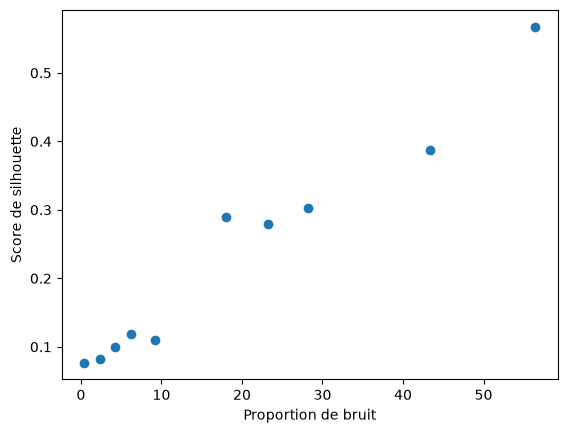

In [20]:
import matplotlib.pyplot as plt

plt.scatter(candidats["%_bruit"], candidats["silhouette"])
plt.xlabel("Proportion de bruit")
plt.ylabel("Score de silhouette")
plt.show()